In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print(df.shape)

(7043, 22)


In [2]:
# Filtering
fiber_monthly = df[(df["InternetService"] == "Fiber optic") & (df["Contract"] == "Month-to-month")]
print("Fiber + month-to-month customers:", len(fiber_monthly))
print("Their churn rate: %.1f%%" % (fiber_monthly["ChurnFlag"].mean() * 100))

# Groupby with multiple statistics
summary = df.groupby("Contract").agg(
    customers=("customerID", "count"),
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    churn_rate=("ChurnFlag", "mean"))
summary["churn_rate"] = (summary["churn_rate"] * 100).round(2)
print(summary.round(2))

# Pivot table
pivot = df.pivot_table(values="ChurnFlag", index="Contract", columns="InternetService", aggfunc="mean") * 100
print(pivot.round(1))

# Creating a new column
df["ChargeCategory"] = pd.cut(df["MonthlyCharges"], [0, 35, 70, 120], labels=["Low", "Medium", "High"])
print(df["ChargeCategory"].value_counts())

# Merging two tables
contract_info = pd.DataFrame({"Contract": ["Month-to-month", "One year", "Two year"],
                              "Commitment_Months": [1, 12, 24]})
merged = df.merge(contract_info, on="Contract", how="left")
print(merged[["customerID", "Contract", "Commitment_Months"]].head())

Fiber + month-to-month customers: 2128
Their churn rate: 54.6%
                customers  avg_tenure  avg_monthly  churn_rate
Contract                                                      
Month-to-month       3875       18.04        66.40       42.71
One year             1473       42.04        65.05       11.27
Two year             1695       56.74        60.77        2.83
InternetService   DSL  Fiber optic    No
Contract                                
Month-to-month   32.2         54.6  18.9
One year          9.3         19.3   2.5
Two year          1.9          7.2   0.8
ChargeCategory
High      3583
Low       1735
Medium    1725
Name: count, dtype: int64
   customerID        Contract  Commitment_Months
0  7590-VHVEG  Month-to-month                  1
1  5575-GNVDE        One year                 12
2  3668-QPYBK  Month-to-month                  1
3  7795-CFOCW        One year                 12
4  9237-HQITU  Month-to-month                  1


In [3]:
charges = df["MonthlyCharges"].to_numpy()
print("Mean:", np.mean(charges).round(2))
print("Median:", np.median(charges))
print("Std dev:", np.std(charges).round(2))
print("25th, 75th percentile:", np.percentile(charges, [25, 75]))

# Z-scores and a simple outlier check
z = (charges - charges.mean()) / charges.std()
print("Customers with |z| > 2:", int((np.abs(z) > 2).sum()))

# Conditional logic with np.where
df["Loyalty"] = np.where(df["tenure"] >= 24, "Loyal", "New")
print(df["Loyalty"].value_counts())

# Correlation matrix
print(np.corrcoef(df["tenure"], df["MonthlyCharges"]).round(3))

Mean: 64.76
Median: 70.35
Std dev: 30.09
25th, 75th percentile: [35.5  89.85]
Customers with |z| > 2: 0
Loyalty
Loyal    3927
New      3116
Name: count, dtype: int64
[[1.    0.248]
 [0.248 1.   ]]


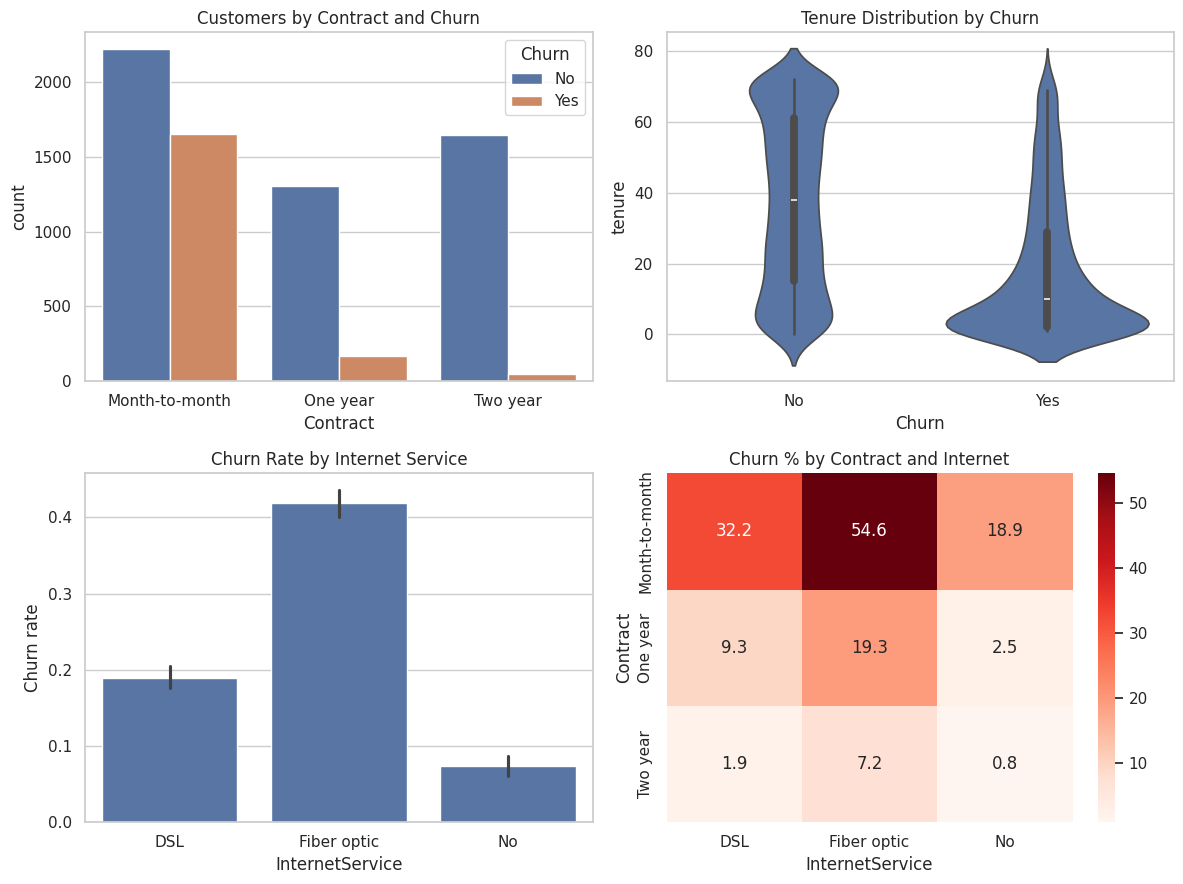

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Customers by Contract and Churn")

sns.violinplot(data=df, x="Churn", y="tenure", ax=axes[0, 1])
axes[0, 1].set_title("Tenure Distribution by Churn")

sns.barplot(data=df, x="InternetService", y="ChurnFlag", ax=axes[1, 0])
axes[1, 0].set_title("Churn Rate by Internet Service"); axes[1, 0].set_ylabel("Churn rate")

sns.heatmap(pivot.round(1), annot=True, cmap="Reds", fmt=".1f", ax=axes[1, 1])
axes[1, 1].set_title("Churn % by Contract and Internet")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

for c in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})

X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "ChurnFlag", "ChargeCategory", "Loyalty"]), drop_first=True)
y = df["ChurnFlag"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=42, n_jobs=-1),
}
for name, m in models.items():
    cv = cross_val_score(m, Xtr, ytr, cv=5, scoring="roc_auc")
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    print(f"\n{name}")
    print("5-fold CV ROC-AUC: %.3f (+/- %.3f)" % (cv.mean(), cv.std()))
    print("Test ROC-AUC: %.3f" % roc_auc_score(yte, p))
    print(classification_report(yte, m.predict(Xte)))


Logistic Regression
5-fold CV ROC-AUC: 0.845 (+/- 0.014)
Test ROC-AUC: 0.841
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Random Forest
5-fold CV ROC-AUC: 0.842 (+/- 0.013)
Test ROC-AUC: 0.841
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      1035
           1       0.57      0.70      0.63       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.74      1409
weighted avg       0.80      0.78      0.79      1409

